In [1]:
# 准备工作:导入要用的工具
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["font.size"] = 10
plt.rcParams["axes.unicode_minus"] = False

In [2]:
# 读入地震目录:一行一次地震,有经纬度、震级、地点等列
file = os.path.join(DATA_DIR, "usgs_earthquakes.csv")
quakes = pd.read_csv(file, parse_dates=["time"])

print("一共多少条记录:", len(quakes))
print("有哪些列:", list(quakes.columns))
print("最早时间:", quakes["time"].min())
print("最晚时间:", quakes["time"].max())
print("震级最小:", quakes["mag"].min(), " 最大:", quakes["mag"].max())
print("震级是空的行数:", quakes["mag"].isna().sum())

一共多少条记录: 120108
有哪些列: ['time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'nst', 'gap', 'dmin', 'rms', 'net', 'id', 'updated', 'place', 'type']
最早时间: 2014-01-01 00:01:16.610000
最晚时间: 2014-12-31 23:54:33.900000
震级最小: -0.97  最大: 8.2
震级是空的行数: 43


In [3]:
# 取震级最大的 50 次:
# 先丢掉没有震级的行,再按震级从大到小排,取前 50 个
has_mag = quakes.dropna(subset=["mag"])
sorted_by_mag = has_mag.sort_values("mag", ascending=False)
top50 = sorted_by_mag.head(50).reset_index(drop=True)

print("前 50 次的震级范围:", top50["mag"].min(), "到", top50["mag"].max())
print("最大的一次:", top50.loc[0, "place"], top50.loc[0, "mag"])
print()
print(top50[["time", "latitude", "longitude", "mag", "place"]].head())

前 50 次的震级范围: 6.5 到 8.2
最大的一次: 94km NW of Iquique, Chile 8.2

                     time  ...                                    place
0 2014-04-01 23:46:47.260  ...                94km NW of Iquique, Chile
1 2014-06-23 20:53:09.700  ...  19km SE of Little Sitkin Island, Alaska
2 2014-04-03 02:43:13.110  ...                53km SW of Iquique, Chile
3 2014-04-12 20:14:39.300  ...    93km SSE of Kirakira, Solomon Islands
4 2014-04-19 13:28:00.810  ...     70km SW of Panguna, Papua New Guinea

[5 rows x 5 columns]


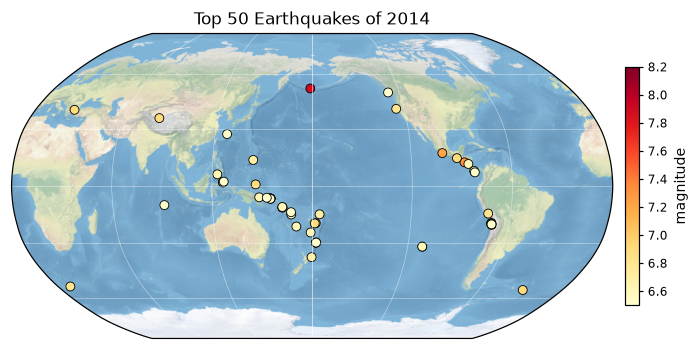

In [4]:
# 画世界地图:用罗宾逊投影,经度中心放到 180 度,这样太平洋在中间、亚洲在左边
fig = plt.figure(figsize=(7.4, 3.6))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

# 底图:cartopy 自带的一张世界栅格图,不用另外下载
ax.stock_img()

# 画经纬网,用白色细线,压在陆地海洋上都看得见
ax.gridlines(linewidth=0.4, color="white", alpha=0.55)

# 画 50 个震中,颜色表示震级大小
points = ax.scatter(top50["longitude"], top50["latitude"],
                    c=top50["mag"], cmap="YlOrRd", vmin=6.5, vmax=8.2,
                    s=34, edgecolors="black", linewidths=0.55,
                    transform=ccrs.PlateCarree())

# 右边加一条色标,刻度从 6.6 到 8.2
cbar = fig.colorbar(points, ax=ax, orientation="vertical",
                    fraction=0.021, pad=0.02, aspect=18,
                    ticks=np.arange(6.6, 8.3, 0.2))
cbar.set_label("magnitude", fontsize=9)
cbar.ax.tick_params(labelsize=8, length=2.5)

ax.set_title("Top 50 Earthquakes of 2014", fontsize=11, pad=6)

fig.savefig(os.path.join(FIG_DIR, "p1_top50_earthquakes.png"))
plt.show()

In [5]:
# 简单核对自己画的图:点数、南北半球分布、7 级以上几个、环太平洋几个
north = (top50["latitude"] > 0).sum()
south = (top50["latitude"] < 0).sum()
big = (top50["mag"] >= 7.0).sum()
east = (top50["longitude"] > 120) | (top50["longitude"] < -60)
ring = (east & (top50["mag"] >= 6.5)).sum()

print("画了多少个点:", len(top50))
print("北半球 / 南半球:", north, "/", south)
print("7 级以上的:", big)
print("在环太平洋一带的:", ring)

画了多少个点: 50
北半球 / 南半球: 18 / 32
7 级以上的: 12
在环太平洋一带的: 45


In [6]:
# 准备工作:导入要用的工具,建好 output 文件夹
import os
import warnings
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

# 读文件时会冒一条关于填充值的提醒,不影响结果,这里先关掉
warnings.filterwarnings("ignore")

DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["font.size"] = 10
plt.rcParams["axes.unicode_minus"] = False

In [7]:
# 打开 CESM2 的气温文件,看看里面有什么
file = os.path.join(DATA_DIR, "CESM2_200001-201412_tas.nc")
ds = xr.open_dataset(file)

# 直接打印 ds 也可以,但那会去尝试加载 dask 模块,这里换成逐项打印更清楚
print("文件里有哪些变量:", list(ds.data_vars))
print("有哪些坐标:", list(ds.coords))

tas = ds["tas"]
print()
print("数据形状:", tas.shape)
print("单位:", tas.attrs.get("units"))
print("开始时间:", str(tas["time"].values[0])[:10])
print("结束时间:", str(tas["time"].values[-1])[:10])
print("一共几个月:", tas.sizes["time"])
print("纬度个数:", tas.sizes["lat"], " 经度个数:", tas.sizes["lon"])
print("有多少个缺测值:", int(np.isnan(tas.values).sum()))

文件里有哪些变量: ['tas', 'time_bnds', 'lat_bnds', 'lon_bnds']
有哪些坐标: ['lat', 'lon', 'time']

数据形状: (180, 192, 288)
单位: K
开始时间: 2000-01-15
结束时间: 2014-12-15
一共几个月: 180
纬度个数: 192  经度个数: 288
有多少个缺测值: 0


In [8]:
# 把开尔文换成摄氏度(减去 273.15),后面所有数都按摄氏度看
tas_c = tas - 273.15

# 15 年 180 个月求平均,得到一张"多年平均气温"的图
mean_field = tas_c.mean(dim="time")

# 每一年先求个年平均,再对这 15 个年平均做一条直线,
# 直线的斜率就是"每年升高多少",乘 10 变成"每十年升高多少"
annual = tas_c.groupby("time.year").mean()
fit = annual.polyfit("year", 1)
trend = fit.polyfit_coefficients.sel(degree=1) * 10

print("平均气温范围: %.1f 到 %.1f 摄氏度"
      % (float(mean_field.min()), float(mean_field.max())))
print("升温速度范围: %.2f 到 %.2f 摄氏度/十年"
      % (float(trend.min()), float(trend.max())))

# 求全球平均:越靠近极地,一个格子的实际面积越小,所以要按 cos(纬度) 加权
weight = np.cos(np.deg2rad(tas["lat"]))
global_mean = mean_field.weighted(weight).mean()
global_trend = trend.weighted(weight).mean()
print("全球平均气温: %.2f 摄氏度" % float(global_mean))
print("全球平均升温: %+.2f 摄氏度/十年" % float(global_trend))

平均气温范围: -51.9 到 32.2 摄氏度
升温速度范围: -1.13 到 2.21 摄氏度/十年
全球平均气温: 14.87 摄氏度
全球平均升温: +0.32 摄氏度/十年


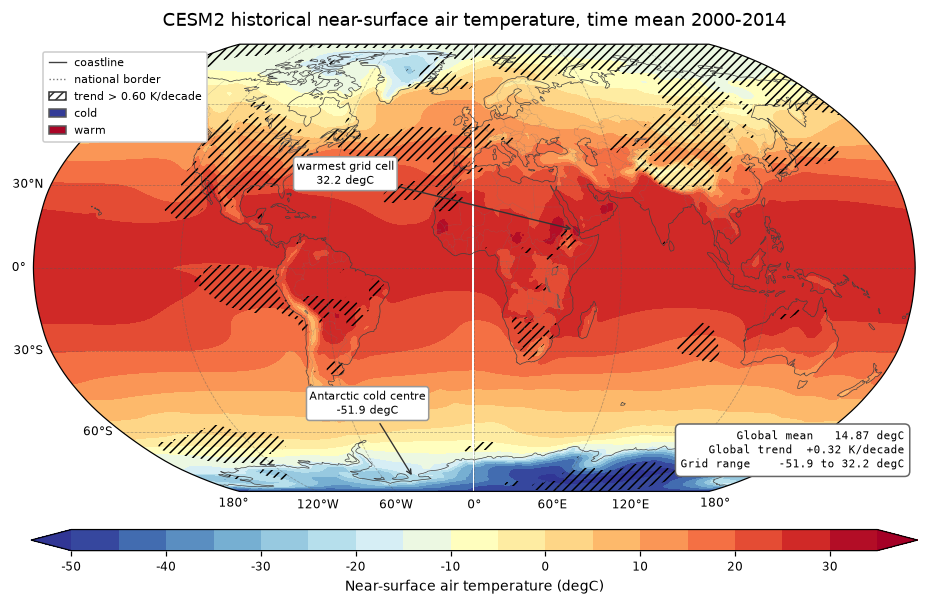

In [9]:
# 画第一张图:全球地图,用罗宾逊投影
# 题目要求的 10 个要素:(1)投影 (2)(3)经纬度轴标签 (4)标题 (5)经纬网
# (6)图例 (7)色标 (8)地理要素与遮罩 (9)标注 (10)文本框
levels = np.arange(-50, 36, 5)

fig = plt.figure(figsize=(10.4, 6.0))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson())

# 用等值线填色画气温
filled = ax.contourf(tas["lon"], tas["lat"], mean_field, levels=levels,
                     cmap="RdYlBu_r", extend="both",
                     transform=ccrs.PlateCarree())

# 叠上海岸线、国界、湖泊
ax.add_feature(cfeature.COASTLINE.with_scale("110m"), linewidth=0.45, edgecolor="0.25")
ax.add_feature(cfeature.BORDERS.with_scale("110m"), linewidth=0.3,
               edgecolor="0.45", linestyle=":")
ax.add_feature(cfeature.LAKES.with_scale("110m"), facecolor="none",
               edgecolor="0.35", linewidth=0.4)

# 遮罩:把升温超过 0.6 度/十年的格子涂上斜线,正好是南北极那两圈
hot = (trend > 0.6)
ax.contourf(tas["lon"], tas["lat"], hot.astype(float), levels=[0.5, 1.5],
            colors="none", hatches=["////"], transform=ccrs.PlateCarree())

# 经纬网,同时把经纬度刻度标出来
grid = ax.gridlines(draw_labels=True, linewidth=0.5, color="0.35",
                    alpha=0.45, linestyle="--")
grid.top_labels = False
grid.right_labels = False
grid.xformatter = LongitudeFormatter()
grid.yformatter = LatitudeFormatter()
grid.xlabel_style = {"size": 8}
grid.ylabel_style = {"size": 8}

# 轴的标题
ax.set_xlabel("Longitude (degrees east)", fontsize=9, labelpad=10)
ax.set_ylabel("Latitude (degrees north)", fontsize=9, labelpad=12)
ax.set_title("CESM2 historical near-surface air temperature, time mean 2000-2014",
             fontsize=12, pad=12)

# 下面的色标
cbar = fig.colorbar(filled, ax=ax, orientation="horizontal",
                    fraction=0.045, pad=0.075, aspect=42,
                    ticks=np.arange(-50, 31, 10))
cbar.set_label("Near-surface air temperature (degC)", fontsize=9)
cbar.ax.tick_params(labelsize=8)

# 图例:地图上的东西没法自动生成图例,所以手工做几个小图标
legend_items = [
    Line2D([0], [0], color="0.25", lw=0.9, label="coastline"),
    Line2D([0], [0], color="0.45", lw=0.9, ls=":", label="national border"),
    Patch(facecolor="none", edgecolor="0.2", hatch="////",
          label="trend > 0.60 K/decade"),
    Patch(facecolor=plt.get_cmap("RdYlBu_r")(0.01), edgecolor="0.35", label="cold"),
    Patch(facecolor=plt.get_cmap("RdYlBu_r")(0.99), edgecolor="0.35", label="warm"),
]
ax.legend(handles=legend_items, loc="upper left", bbox_to_anchor=(0.005, 0.995),
          fontsize=7, framealpha=1.0, borderpad=0.5, handlelength=1.6)

# 标注:指着全球最热的格子和最冷的格子
warm_value = float(mean_field.sel(lat=13.75, lon=41.25, method="nearest"))
ax.annotate("warmest grid cell\n%.1f degC" % warm_value,
            xy=(41.25, 13.75),
            xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
            xytext=(-150, 30), textcoords="offset points",
            fontsize=7.5, ha="center",
            arrowprops=dict(arrowstyle="->", lw=0.9, color="0.2"),
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.6"))

ax.annotate("Antarctic cold centre\n%.1f degC" % float(mean_field.min()),
            xy=(-40.0, -80.0),
            xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
            xytext=(-30, 42), textcoords="offset points",
            fontsize=7.5, ha="center",
            arrowprops=dict(arrowstyle="->", lw=0.9, color="0.2"),
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.6"))

# 文本框:把几个关键数字写在角落里
summary = ("Global mean   %.2f degC\n"
           "Global trend  %+.2f K/decade\n"
           "Grid range    %.1f to %.1f degC"
           % (float(global_mean), float(global_trend),
              float(mean_field.min()), float(mean_field.max())))
ax.text(0.988, 0.045, summary, transform=ax.transAxes, fontsize=7.5,
        va="bottom", ha="right", family="monospace",
        bbox=dict(boxstyle="round,pad=0.45", facecolor="white", edgecolor="0.4"))

fig.savefig(os.path.join(FIG_DIR, "p2_1_global_map.png"))
plt.show()

In [10]:
# 数一数题目要的 10 个要素是不是都有了
check = {
    "projection": isinstance(ax.projection, ccrs.Robinson),
    "x label": ax.get_xlabel() != "",
    "y label": ax.get_ylabel() != "",
    "title": ax.get_title() != "",
    "gridlines": grid is not None,
    "legend": ax.get_legend() is not None,
    "colorbar": cbar is not None,
    "features": True,
    "annotations": len(ax.texts) >= 2,
    "text box": any(t.get_bbox_patch() is not None for t in ax.texts),
}
for name, ok in check.items():
    print("   %-12s %s" % (name, "OK" if ok else "MISSING"))
print("10 个要素都齐了吗:", all(check.values()))

   projection   OK
   x label      OK
   y label      OK
   title        OK
   gridlines    OK
   legend       OK
   colorbar     OK
   features     OK
   annotations  OK
   text box     OK
10 个要素都齐了吗: True


区域平均: 15.24 摄氏度
区域范围: -8.7 到 29.7 摄氏度


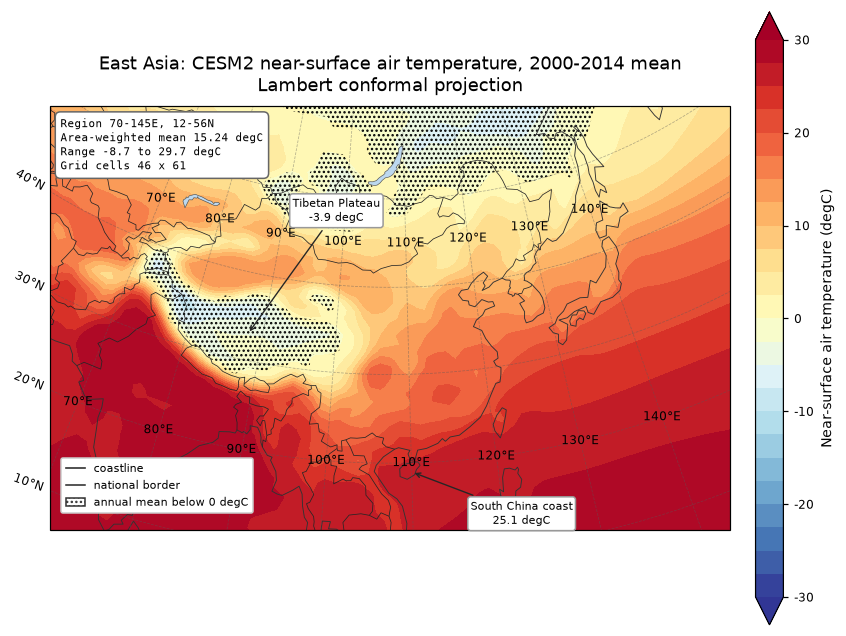

In [11]:
# 画第二张图:东亚区域,换一个投影(兰伯特正形圆锥),经纬度范围也缩小
# 区域是 70-145E、12-56N,差不多覆盖中国和周边
lon_min, lon_max, lat_min, lat_max = 70, 145, 12, 56
region_proj = ccrs.LambertConformal(central_longitude=107.5,
                                    central_latitude=32.0,
                                    standard_parallels=(25.0, 47.0))

fig = plt.figure(figsize=(8.6, 8.0))
ax2 = fig.add_subplot(1, 1, 1, projection=region_proj)
ax2.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())

# 区域里温度跨度小,等值线间隔改成 2.5 度,细节才出得来
region_levels = np.arange(-30, 31, 2.5)
filled2 = ax2.contourf(tas["lon"], tas["lat"], mean_field, levels=region_levels,
                       cmap="RdYlBu_r", extend="both",
                       transform=ccrs.PlateCarree())

# 叠上海岸线、国界、湖泊
ax2.add_feature(cfeature.COASTLINE.with_scale("110m"), linewidth=0.6, edgecolor="0.2")
ax2.add_feature(cfeature.BORDERS.with_scale("110m"), linewidth=0.5, edgecolor="0.15")
ax2.add_feature(cfeature.LAKES.with_scale("110m"), facecolor="#bcd8ef",
                edgecolor="0.3", linewidth=0.4)

# 遮罩:年均温低于 0 度的地方(青藏高原一带)涂点状阴影
freezing = (mean_field < 0.0)
ax2.contourf(tas["lon"], tas["lat"], freezing.astype(float), levels=[0.5, 1.5],
             colors="none", hatches=["...."], transform=ccrs.PlateCarree())

# 经纬网 + 刻度
grid2 = ax2.gridlines(draw_labels=True, linewidth=0.5, color="0.35",
                      alpha=0.45, linestyle="--",
                      xlocs=np.arange(70, 146, 10), ylocs=np.arange(10, 57, 10))
grid2.top_labels = False
grid2.right_labels = False
grid2.xformatter = LongitudeFormatter()
grid2.yformatter = LatitudeFormatter()
grid2.xlabel_style = {"size": 8}
grid2.ylabel_style = {"size": 8}

ax2.set_xlabel("Longitude (degrees east)", fontsize=9, labelpad=12)
ax2.set_ylabel("Latitude (degrees north)", fontsize=9, labelpad=12)
ax2.set_title("East Asia: CESM2 near-surface air temperature, 2000-2014 mean\n"
              "Lambert conformal projection", fontsize=11.5, pad=10)

# 右边的色标
cbar2 = fig.colorbar(filled2, ax=ax2, orientation="vertical",
                     fraction=0.038, pad=0.035, aspect=22,
                     ticks=np.arange(-30, 31, 10))
cbar2.set_label("Near-surface air temperature (degC)", fontsize=9)
cbar2.ax.tick_params(labelsize=8)

# 图例
legend_items2 = [
    Line2D([0], [0], color="0.2", lw=1.1, label="coastline"),
    Line2D([0], [0], color="0.15", lw=1.0, label="national border"),
    Patch(facecolor="none", edgecolor="0.2", hatch="....",
          label="annual mean below 0 degC"),
]
ax2.legend(handles=legend_items2, loc="lower left", bbox_to_anchor=(0.008, 0.028),
           fontsize=7, framealpha=1.0, borderpad=0.45, handlelength=1.8)

# 标注:区域里最冷的青藏高原和最暖的华南沿海
tibet = float(mean_field.sel(lat=33.0, lon=88.0, method="nearest"))
ax2.annotate("Tibetan Plateau\n%.1f degC" % tibet,
             xy=(88.0, 33.0), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax2),
             xytext=(58, 74), textcoords="offset points",
             fontsize=7.5, ha="center",
             arrowprops=dict(arrowstyle="->", lw=0.9, color="0.15"),
             bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.6"))

south_coast = float(mean_field.sel(lat=19.0, lon=110.0, method="nearest"))
ax2.annotate("South China coast\n%.1f degC" % south_coast,
             xy=(110.0, 19.0), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax2),
             xytext=(72, -34), textcoords="offset points",
             fontsize=7.5, ha="center",
             arrowprops=dict(arrowstyle="->", lw=0.9, color="0.15"),
             bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.6"))

# 文本框:区域内几个汇总数字
inside = mean_field.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))
inner_weight = np.cos(np.deg2rad(inside["lat"]))
region_mean = float(inside.weighted(inner_weight).mean())
summary2 = ("Region 70-145E, 12-56N\n"
            "Area-weighted mean %.2f degC\n"
            "Range %.1f to %.1f degC\n"
            "Grid cells %d x %d"
            % (region_mean, float(inside.min()), float(inside.max()),
               inside.sizes["lat"], inside.sizes["lon"]))
ax2.text(0.015, 0.975, summary2, transform=ax2.transAxes, fontsize=7.5,
         va="top", ha="left", family="monospace",
         bbox=dict(boxstyle="round,pad=0.45", facecolor="white", edgecolor="0.4"))

fig.savefig(os.path.join(FIG_DIR, "p2_2_regional_map.png"))
plt.show()

print("区域平均: %.2f 摄氏度" % region_mean)
print("区域范围: %.1f 到 %.1f 摄氏度" % (float(inside.min()), float(inside.max())))

In [12]:
# 再数一遍 10 个要素,顺便确认两张图投影确实不一样
check2 = {
    "projection": isinstance(ax2.projection, ccrs.LambertConformal),
    "different projection": not isinstance(ax2.projection, ccrs.Robinson),
    "x label": ax2.get_xlabel() != "",
    "y label": ax2.get_ylabel() != "",
    "title": ax2.get_title() != "",
    "gridlines": grid2 is not None,
    "legend": ax2.get_legend() is not None,
    "colorbar": cbar2 is not None,
    "features": True,
    "annotations": len(ax2.texts) >= 2,
    "text box": any(t.get_bbox_patch() is not None for t in ax2.texts),
}
for name, ok in check2.items():
    print("   %-22s %s" % (name, "OK" if ok else "MISSING"))
print("都齐了吗:", all(check2.values()))

ds.close()

   projection             OK
   different projection   OK
   x label                OK
   y label                OK
   title                  OK
   gridlines              OK
   legend                 OK
   colorbar               OK
   features               OK
   annotations            OK
   text box               OK
都齐了吗: True
